In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
# transfering Final_data into a dataframe

In [3]:
df = pd.read_csv('Final_data.csv')

print(df)

          country  year     sex          age  suicide_no  population  \
0         Albania  1987    male  15-24 years          21      312900   
1         Albania  1987    male  35-54 years          16      308000   
2         Albania  1987  female  15-24 years          14      289700   
3         Albania  1987    male    75+ years           1       21800   
4         Albania  1987    male  25-34 years           9      274300   
...           ...   ...     ...          ...         ...         ...   
27815  Uzbekistan  2014  female  35-54 years         107     3620833   
27816  Uzbekistan  2014  female    75+ years           9      348465   
27817  Uzbekistan  2014    male   5-14 years          60     2762158   
27818  Uzbekistan  2014  female   5-14 years          44     2631600   
27819  Uzbekistan  2014  female  55-74 years          21     1438935   

       suicides_per_100k  gdp_for_year_usd  gdp_per_capita       generation  \
0                   6.71        2156624900             7

In [4]:
df.shape
#gives us the number of rows and columns

(27820, 12)

In [5]:
df.head()
#checking if the start of the file is correct


,country,year,sex,age,suicide_no,population,suicides_per_100k,gdp_for_year_usd,gdp_per_capita,generation,decade,age_order
0,Albania,1987,male,15-24 years,21,312900,6.71,2156624900,796,Generation X,1980,2
1,Albania,1987,male,35-54 years,16,308000,5.19,2156624900,796,Silent,1980,4
2,Albania,1987,female,15-24 years,14,289700,4.83,2156624900,796,Generation X,1980,2
3,Albania,1987,male,75+ years,1,21800,4.59,2156624900,796,G.I. Generation,1980,6
4,Albania,1987,male,25-34 years,9,274300,3.28,2156624900,796,Boomers,1980,3


In [6]:
df.tail()
#checking if the end of the file is correct

,country,year,sex,age,suicide_no,population,suicides_per_100k,gdp_for_year_usd,gdp_per_capita,generation,decade,age_order
27815,Uzbekistan,2014,female,35-54 years,107,3620833,2.96,63067077179,2309,Generation X,2010,4
27816,Uzbekistan,2014,female,75+ years,9,348465,2.58,63067077179,2309,Silent,2010,6
27817,Uzbekistan,2014,male,5-14 years,60,2762158,2.17,63067077179,2309,Generation Z,2010,1
27818,Uzbekistan,2014,female,5-14 years,44,2631600,1.67,63067077179,2309,Generation Z,2010,1
27819,Uzbekistan,2014,female,55-74 years,21,1438935,1.46,63067077179,2309,Boomers,2010,5


In [7]:
df.info()
#This shows:
#Column names
#Non-null counts
#Data types
#Memory usage

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27820 entries, 0 to 27819
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   country            27820 non-null  object 
 1   year               27820 non-null  int64  
 2   sex                27820 non-null  object 
 3   age                27820 non-null  object 
 4   suicide_no         27820 non-null  int64  
 5   population         27820 non-null  int64  
 6   suicides_per_100k  27820 non-null  float64
 7   gdp_for_year_usd   27820 non-null  int64  
 8   gdp_per_capita     27820 non-null  int64  
 9   generation         27820 non-null  object 
 10  decade             27820 non-null  int64  
 11  age_order          27820 non-null  int64  
dtypes: float64(1), int64(7), object(4)
memory usage: 2.5+ MB


In [8]:
df.isna().sum()
#shows any null values

country              0
year                 0
sex                  0
age                  0
suicide_no           0
population           0
suicides_per_100k    0
gdp_for_year_usd     0
gdp_per_capita       0
generation           0
decade               0
age_order            0
dtype: int64

In [9]:
df.duplicated()
#check for duplicates

0        False
1        False
2        False
3        False
4        False
         ...  
27815    False
27816    False
27817    False
27818    False
27819    False
Length: 27820, dtype: bool

In [10]:
#Till now we have done the following

# Load the CSV into a dataframe
# Check shape (rows/columns)
# Preview first/last rows
# Confirm dtypes
# Check missing values
# Check duplicates (especially by country-year-sex-age)

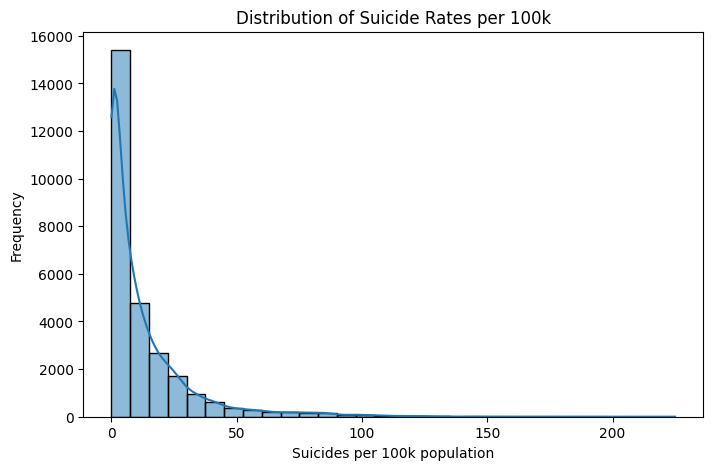

In [11]:
#Distribution of sucides per 100k
plt.figure(figsize=(8, 5))
sns.histplot(df['suicides_per_100k'], bins=30, kde=True)
plt.xlabel("Suicides per 100k population")
plt.ylabel("Frequency")
plt.title("Distribution of Suicide Rates per 100k")
plt.show()

In [12]:
# Count of records by sex
trend_sex = (
    df.groupby(['year', 'sex'])['suicides_per_100k']
      .mean()
      .reset_index()
)

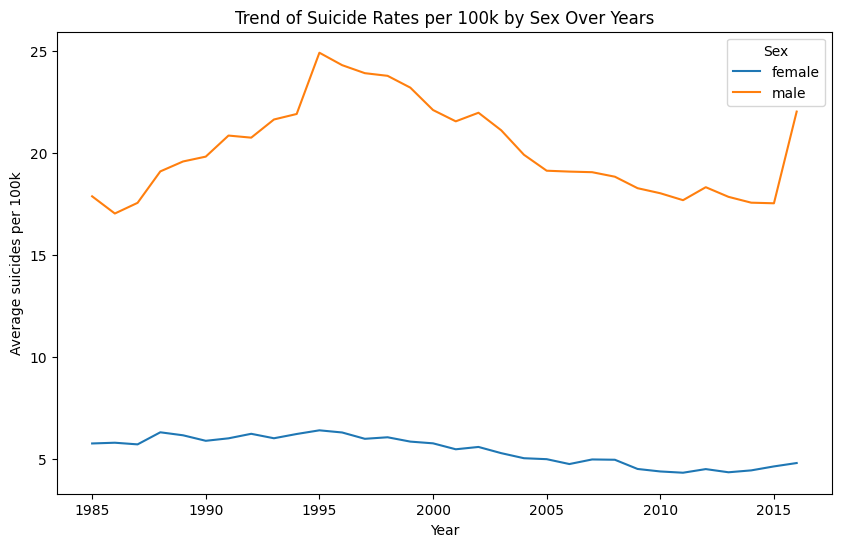

In [13]:
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=trend_sex,
    x='year',
    y='suicides_per_100k',
    hue='sex'
)

plt.title("Trend of Suicide Rates per 100k by Sex Over Years")
plt.xlabel("Year")
plt.ylabel("Average suicides per 100k")
plt.legend(title="Sex")
plt.show()

In [14]:
trend_age = (
    df.groupby(['year', 'age', 'age_order'])['suicides_per_100k']
      .mean()
      .reset_index()
      .sort_values('age_order')
)


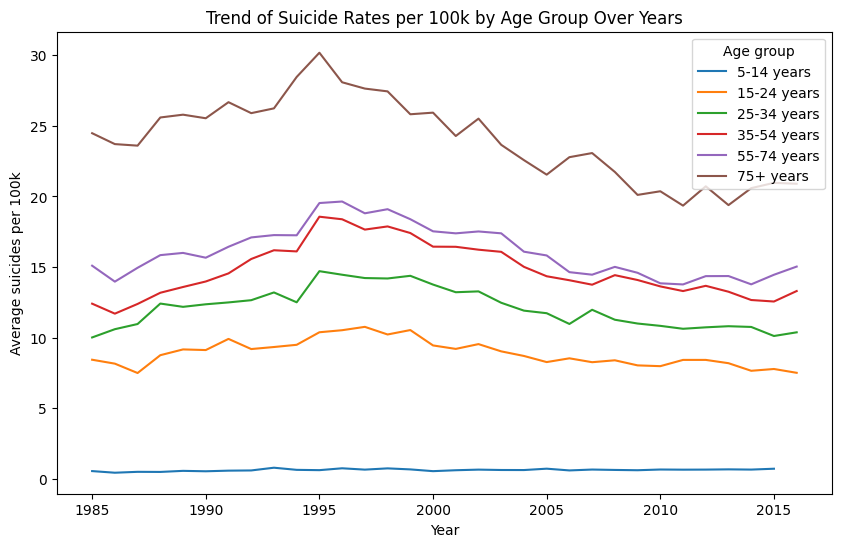

In [15]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=trend_age,
    x='year',
    y='suicides_per_100k',
    hue='age'
)

plt.title("Trend of Suicide Rates per 100k by Age Group Over Years")
plt.xlabel("Year")
plt.ylabel("Average suicides per 100k")
plt.legend(title="Age group")
plt.show()

In [16]:
age_sex = (
    df.groupby(['age', 'age_order', 'sex'])['suicides_per_100k']
      .mean()
      .reset_index()
      .sort_values('age_order')
)


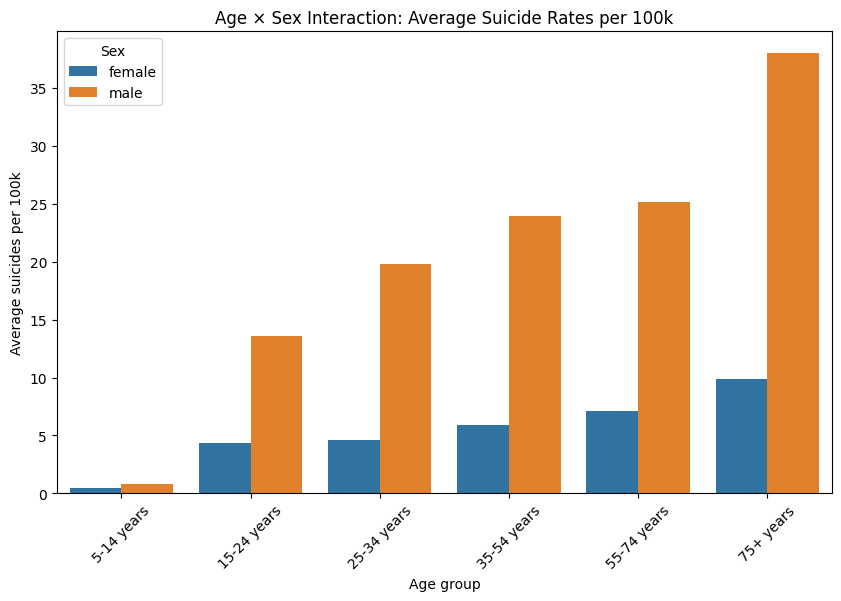

In [17]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=age_sex,
    x='age',
    y='suicides_per_100k',
    hue='sex'
)

plt.title("Age × Sex Interaction: Average Suicide Rates per 100k")
plt.xlabel("Age group")
plt.ylabel("Average suicides per 100k")
plt.legend(title="Sex")
plt.xticks(rotation=45)
plt.show()


In [18]:
# global sucide rate over the years
global_trend = (
    df.groupby('year')['suicides_per_100k']
      .mean()
      .reset_index()
)


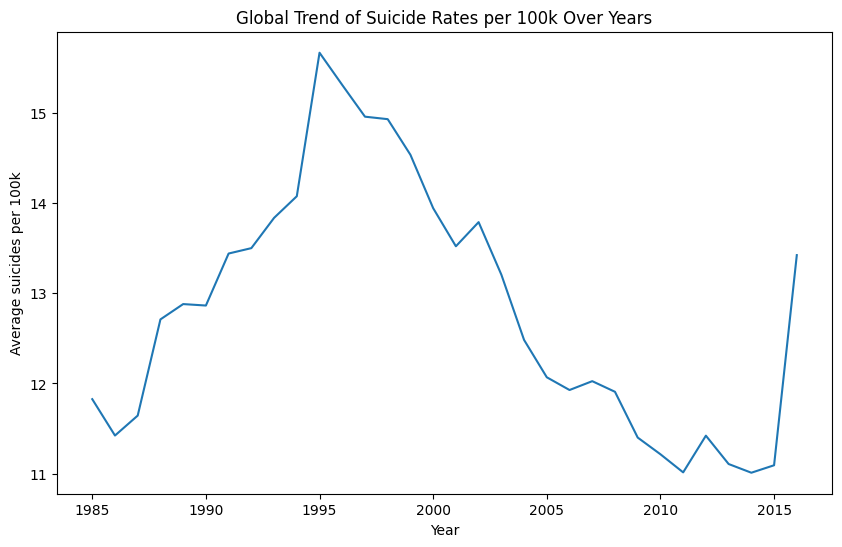

In [19]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=global_trend,
    x='year',
    y='suicides_per_100k'
)

plt.title("Global Trend of Suicide Rates per 100k Over Years")
plt.xlabel("Year")
plt.ylabel("Average suicides per 100k")
plt.show()

In [20]:
# top 10 Countries by average sucide rate
top10_avg_rate = (
    df.groupby('country')['suicides_per_100k']
      .mean()
      .sort_values(ascending=False)
      .head(10)
      .reset_index()

)

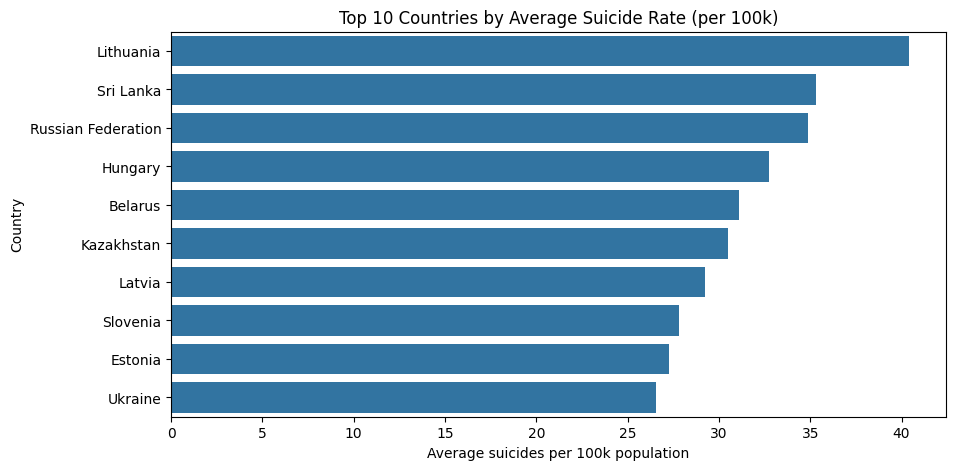

In [22]:
plt.figure(figsize=(10,5))

sns.barplot(
    data = top10_avg_rate,
    x = 'suicides_per_100k',
    y = 'country'
)

plt.title("Top 10 Countries by Average Suicide Rate (per 100k)")
plt.xlabel("Average suicides per 100k population")
plt.ylabel("Country")

plt.show()

In [23]:
top10_total_suicides = (
    df.groupby('country')['suicide_no']
      .sum()
      .sort_values(ascending=False)
      .head(10)
      .reset_index()
)


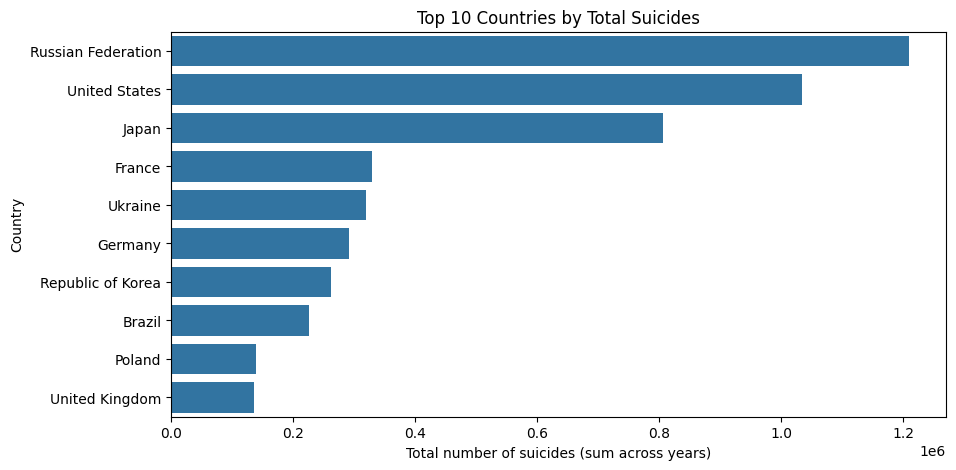

In [24]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=top10_total_suicides,
    x='suicide_no',
    y='country'
)

plt.title("Top 10 Countries by Total Suicides")
plt.xlabel("Total number of suicides (sum across years)")
plt.ylabel("Country")

plt.show()

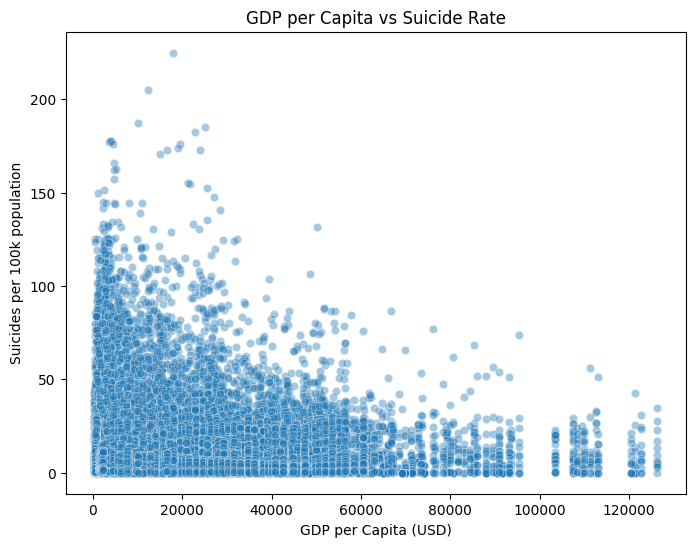

In [25]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='gdp_per_capita',
    y='suicides_per_100k',
    alpha=0.4
)

plt.title("GDP per Capita vs Suicide Rate")
plt.xlabel("GDP per Capita (USD)")
plt.ylabel("Suicides per 100k population")

plt.show()

In [27]:
sex_avg_overall = (
    df.groupby('sex')['suicides_per_100k']
      .mean()
      .reset_index()
)


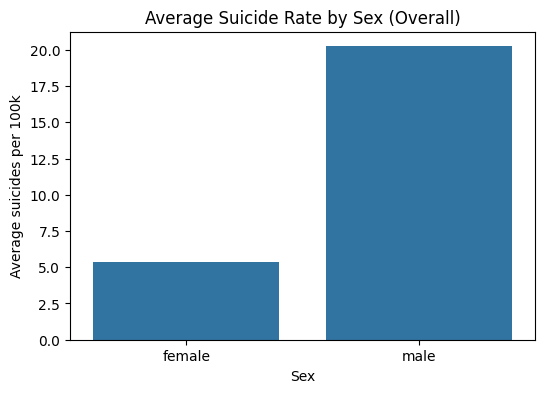

In [28]:
plt.figure(figsize=(6, 4))
sns.barplot(data=sex_avg_overall, x='sex', y='suicides_per_100k')
plt.title("Average Suicide Rate by Sex (Overall)")
plt.xlabel("Sex")
plt.ylabel("Average suicides per 100k")
plt.show()

In [29]:
numeric_cols = df.select_dtypes(include=['int64', 'float64'])


In [30]:
corr_matrix = numeric_cols.corr()


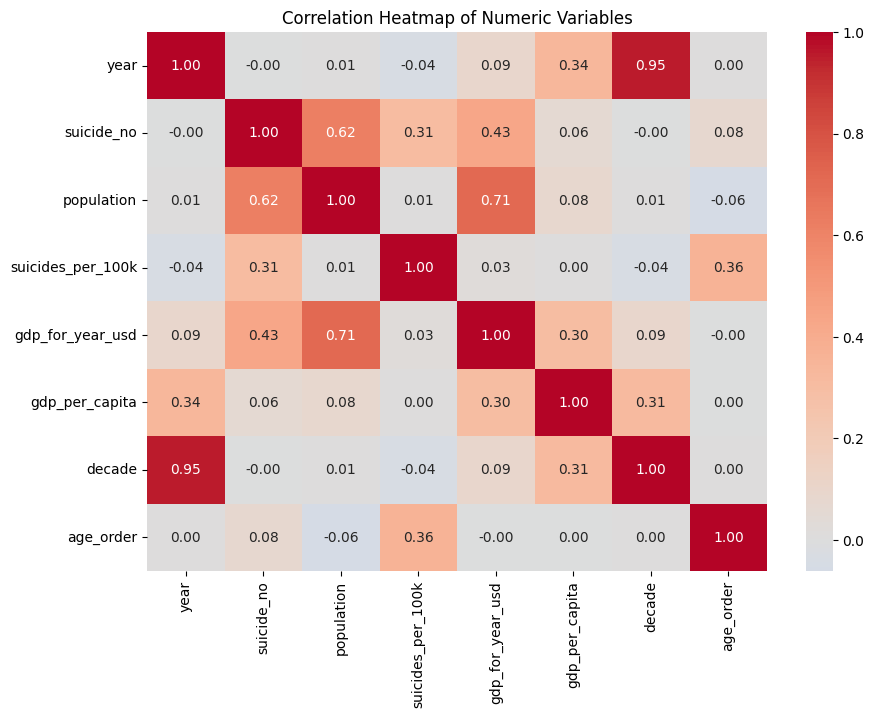

In [31]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numeric Variables")
plt.show()